<a href="https://colab.research.google.com/github/AbhinandLaji/Ai-Ml-lab/blob/main/AI_Cycle_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Q1. Load a dataset and display basic info
url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
df = pd.read_csv(url)

print("--- Basic Information ---")
df.info()

# Q2. Identify rows, columns, data types, and missing values
print(f"\\nNumber of Rows: {df.shape[0]}")
print(f"Number of Columns: {df.shape[1]}")
print("\\nMissing Values per Column:")
print(df.isnull().sum())

# Q3. Exploratory Data Inspection
display(df.head(3))   # First records
display(df.tail(3))   # Last records
display(df.sample(3)) # Random records

--- Basic Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
\nNumber of Rows: 891
Number of Columns: 12
\nMissing Values per Column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch       

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
747,748,1,2,"Sinkkonen, Miss. Anna",female,30.0,0,0,250648,13.0000,NaN,S
420,421,0,3,"Gheorgheff, Mr. Stanio",male,NaN,0,0,349254,7.8958,NaN,C
98,99,1,2,"Doling, Mrs. John T (Ada Julia Bone)",female,34.0,0,1,231919,23.0000,NaN,S


In [5]:
print("--- Q4: Handling Missing Values ---")
print("Missing values BEFORE:")
print(df[['Age', 'Embarked']].isnull().sum())

# Fill missing values
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df = df.drop(columns=['Cabin'], errors='ignore')

print("\nMissing values AFTER:")
print(df[['Age', 'Embarked']].isnull().sum())
print("-" * 40)

print("\n--- Q5: Handling Duplicates ---")
print(f"Duplicates found: {df.duplicated().sum()}")
df = df.drop_duplicates()
print("-" * 40)

print("\n--- Q13: Converting Data Types ---")
print(f"Data type of 'Age' BEFORE: {df['Age'].dtype}")
# Convert float to integer
df['Age'] = df['Age'].astype(int)
print(f"Data type of 'Age' AFTER: {df['Age'].dtype}")
print("-" * 40)

print("\n--- Q14: Handling Inconsistent/Noisy Data ---")
print("Names BEFORE cleaning:")
display(df[['Name']].head(3))

# Convert to lowercase and strip accidental spaces
df['Name'] = df['Name'].str.lower().str.strip()

print("\nNames AFTER cleaning:")
display(df[['Name']].head(3))

--- Q4: Handling Missing Values ---
Missing values BEFORE:
Age         0
Embarked    0
dtype: int64

Missing values AFTER:
Age         0
Embarked    0
dtype: int64
----------------------------------------

--- Q5: Handling Duplicates ---
Duplicates found: 0
----------------------------------------

--- Q13: Converting Data Types ---
Data type of 'Age' BEFORE: int64
Data type of 'Age' AFTER: int64
----------------------------------------

--- Q14: Handling Inconsistent/Noisy Data ---
Names BEFORE cleaning:


,Name
0,"braund, mr. owen harris"
1,"cumings, mrs. john bradley (florence briggs th..."
2,"heikkinen, miss. laina"



Names AFTER cleaning:


,Name
0,"braund, mr. owen harris"
1,"cumings, mrs. john bradley (florence briggs th..."
2,"heikkinen, miss. laina"


--- Q6 & Q7: Detecting and Handling Outliers ('Fare') ---
Maximum Fare BEFORE capping: 512.3292


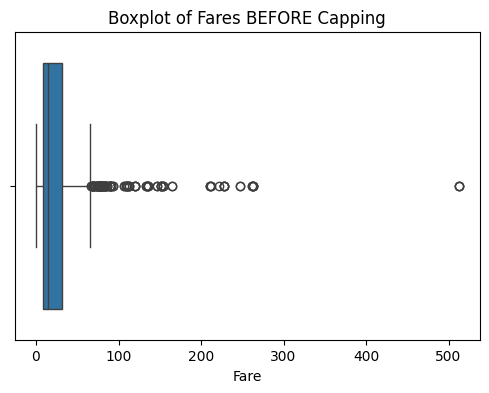


Maximum Fare AFTER capping: 65.6344
----------------------------------------

--- Q12: Feature Engineering ---
New 'FamilySize' feature created:


,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


In [6]:
print("--- Q6 & Q7: Detecting and Handling Outliers ('Fare') ---")
print(f"Maximum Fare BEFORE capping: {df['Fare'].max()}")

# Detect outliers using Box Plots
plt.figure(figsize=(6, 4))
sns.boxplot(x=df['Fare'])
plt.title("Boxplot of Fares BEFORE Capping")
plt.show()

# Handle outliers using Statistical Methods (IQR Capping)
Q1 = df['Fare'].quantile(0.25)
Q3 = df['Fare'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR

# Cap the extreme outliers at the upper limit
df['Fare'] = np.where(df['Fare'] > upper_limit, upper_limit, df['Fare'])

print(f"\nMaximum Fare AFTER capping: {df['Fare'].max()}")
print("-" * 40)

print("\n--- Q12: Feature Engineering ---")
# Combine Siblings/Spouses (SibSp) and Parents/Children (Parch) into 'FamilySize'
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

print("New 'FamilySize' feature created:")
display(df[['SibSp', 'Parch', 'FamilySize']].head(5))

In [7]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler

print("--- Q8: Encoding Categorical Variables ---")
print("Data BEFORE Encoding (Notice 'Sex' and 'Embarked'):")
display(df[['Sex', 'Embarked']].head(3))

# 1. Label Encoding (Sex: male=1, female=0)
le = LabelEncoder()
df['Sex'] = le.fit_transform(df['Sex'])

# 2. One-Hot Encoding ('Embarked' split into new binary columns)
df = pd.get_dummies(df, columns=['Embarked'], drop_first=True)

print("\nData AFTER Encoding:")
# Notice 'Sex' is now numbers, and 'Embarked' has become 'Embarked_Q' & 'Embarked_S'
display(df.head(3))
print("-" * 40)

print("\n--- Q9: Feature Scaling ---")
# 1. Min-Max Normalization (Age scaled between 0 and 1)
min_max = MinMaxScaler()
df['Age_scaled'] = min_max.fit_transform(df[['Age']])

# 2. Standardization / Z-score (Fare scaled to mean=0, std=1)
scaler = StandardScaler()
df['Fare_scaled'] = scaler.fit_transform(df[['Fare']])

print("Data AFTER Scaling (Comparing original to scaled):")
display(df[['Age', 'Age_scaled', 'Fare', 'Fare_scaled']].head(5))

--- Q8: Encoding Categorical Variables ---
Data BEFORE Encoding (Notice 'Sex' and 'Embarked'):


,Sex,Embarked
0,male,S
1,female,C
2,female,S



Data AFTER Encoding:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,FamilySize,Embarked_Q,Embarked_S
0,1,0,3,"braund, mr. owen harris",1,22,1,0,A/5 21171,7.2500,2,False,True
1,2,1,1,"cumings, mrs. john bradley (florence briggs th...",0,38,1,0,PC 17599,65.6344,2,False,False
2,3,1,3,"heikkinen, miss. laina",0,26,0,0,STON/O2. 3101282,7.9250,1,False,True


----------------------------------------

--- Q9: Feature Scaling ---
Data AFTER Scaling (Comparing original to scaled):


,Age,Age_scaled,Fare,Fare_scaled
0,22,0.2750,7.2500,-0.820552
1,38,0.4750,65.6344,2.031623
2,26,0.3250,7.9250,-0.787578
3,35,0.4375,53.1000,1.419297
4,35,0.4375,8.0500,-0.781471


--- Q17: Distribution of Numerical Features ---


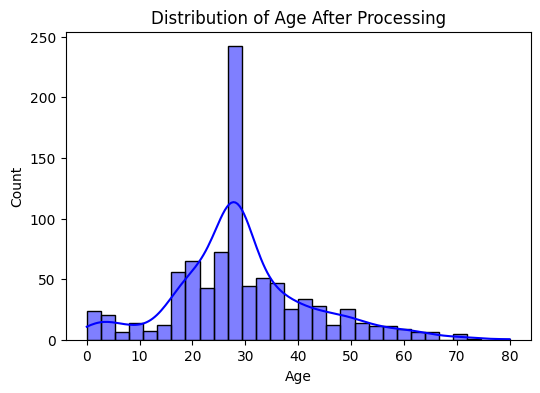

----------------------------------------

--- Q10 & Q11: Correlation Analysis ---
Correlation Matrix (Text Output):


,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,Age_scaled,Fare_scaled
PassengerId,1.000000,-0.005007,-0.035144,0.042939,0.034322,-0.057527,-0.001652,0.003243,-0.040143,0.034322,0.003243
Survived,-0.005007,1.000000,-0.338481,-0.543351,-0.064909,-0.035322,0.081629,0.317430,0.016639,-0.064909,0.317430
Pclass,-0.035144,-0.338481,1.000000,0.131900,-0.339999,0.083081,0.018443,-0.715300,0.065997,-0.339999,-0.715300


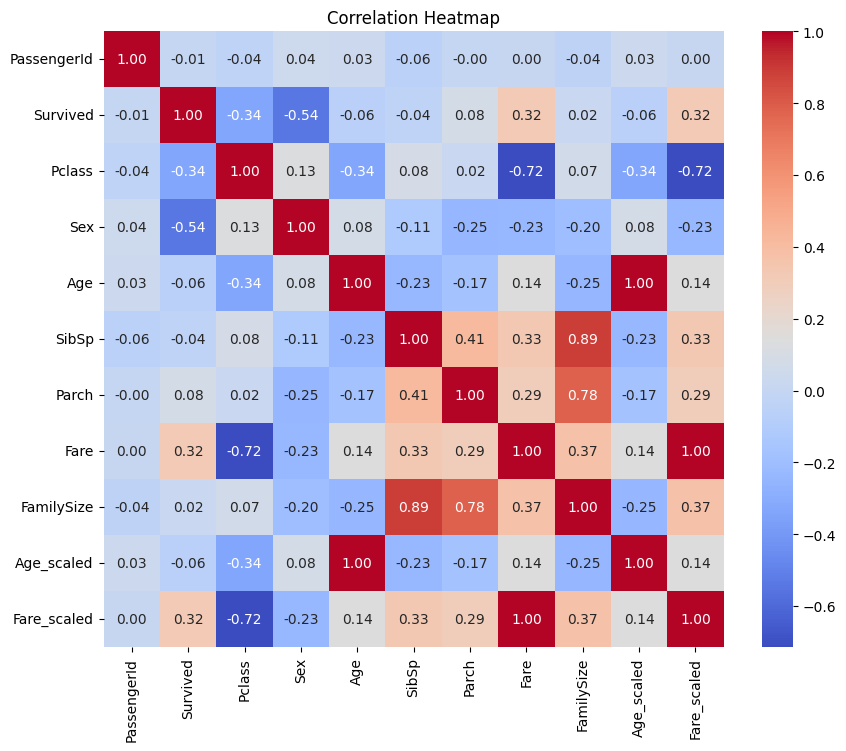

In [8]:
print("--- Q17: Distribution of Numerical Features ---")
plt.figure(figsize=(6, 4))
sns.histplot(df['Age'], kde=True, color='blue')
plt.title("Distribution of Age After Processing")
plt.show()
print("-" * 40)

print("\n--- Q10 & Q11: Correlation Analysis ---")
# We only want to correlate numerical columns, so we drop text-based ones like Name/Ticket
numeric_df = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_df.corr()

print("Correlation Matrix (Text Output):")
display(correlation_matrix.head(3))

# Generate Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [9]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Drop non-numeric/text columns that our model can't process
X = df.drop(columns=['Survived', 'Name', 'Ticket', 'PassengerId'])
y = df['Survived']

# Q15. Split dataset into training (80%) and testing sets (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Q16. Perform data balancing using SMOTE
print("--- Q16 & Q18: Splitting and Balancing Data ---")
print(f"Original Training Data Size (Before SMOTE): {X_train.shape[0]} rows")
print(f"Target variable distribution BEFORE SMOTE:\n{y_train.value_counts()}\n")

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print(f"Balanced Training Data Size (After SMOTE): {X_train_balanced.shape[0]} rows")
print(f"Target variable distribution AFTER SMOTE:\n{y_train_balanced.value_counts()}")
print("-" * 40)

# Q19. Save the cleaned and preprocessed dataset
print("\n--- Q19: Exporting Dataset ---")
cleaned_df = pd.concat([X, y], axis=1)
cleaned_df.to_csv('cleaned_titanic_dataset.csv', index=False)
print("SUCCESS: Cleaned dataset saved as 'cleaned_titanic_dataset.csv'!")
display(cleaned_df.head(3))

--- Q16 & Q18: Splitting and Balancing Data ---
Original Training Data Size (Before SMOTE): 712 rows
Target variable distribution BEFORE SMOTE:
Survived
0    444
1    268
Name: count, dtype: int64

Balanced Training Data Size (After SMOTE): 888 rows
Target variable distribution AFTER SMOTE:
Survived
0    444
1    444
Name: count, dtype: int64
----------------------------------------

--- Q19: Exporting Dataset ---
SUCCESS: Cleaned dataset saved as 'cleaned_titanic_dataset.csv'!


,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,Embarked_Q,Embarked_S,Age_scaled,Fare_scaled,Survived
0,3,1,22,1,0,7.2500,2,False,True,0.275,-0.820552,0
1,1,0,38,1,0,65.6344,2,False,False,0.475,2.031623,1
2,3,0,26,0,0,7.9250,1,False,True,0.325,-0.787578,1
